# Human Validation der Faktenrelevanz – Ergebnisse

## Ergebnisüberblick
Die zentrale Frage ist, ob das Modell relevante Fakten für den nachfolgenden QA-Fragensatz auswählt. Besonders aussagekräftig sind die **Top-20-Qualität**, die **Erfassung menschlicher Core-Fakten**, Unterschiede zwischen Artikeln, die **Kalibrierung der Modelllabels** und die **Übereinstimmung der Teilnehmer**. Die folgenden fünf Abbildungen beantworten diese Fragen; Abbildungen 1–3 eignen sich besonders für den Hauptergebnisteil, Abbildungen 4–5 für Reliabilität und Rankingdiagnostik.

## Kontext und Methoden
- Datenquelle: `human_validation_faktenrelevanz_ergebnisse.csv`, im selben Arbeitsverzeichnis wie das Notebook.
- Umfang: fünf formale Validierungsartikel, 168 Kandidatenfakten und fünf Teilnehmer; 840 Einzelbewertungen. Der Kalibrierungsartikel ist ausgeschlossen.
- Kodierung: Peripheral = 0, Supporting = 1, Core = 2. Menschlicher Konsens: Median der fünf Bewertungen. Als relevant gelten Core und Supporting.
- Modellranking: Rang 1 bezeichnet den wichtigsten Fakt; Top 20 sind je Artikel ausgewählt.
- Precision@20: Anteil menschlich relevanter Fakten in den Top 20. Core-Recall@20: erfasste Core-Fakten / alle menschlichen Core-Fakten des Artikels.
- nDCG@20 mit linearem Gain 0/1/2: Rangqualität relativ zur idealen menschlichen Sortierung; Peripheral trägt keinen Gain bei.
- Zusätzlich wird das ursprüngliche nDCG aus der eingefrorenen Analyse reproduziert: exponentieller Gain auf der ursprünglichen Skala 1/2/3 (Gain 1/3/7). Beide Definitionen werden ausdrücklich unterschieden.

### Annahmen und Grenzen
Der Median ist ein aggregiertes subjektives Urteil. Fakten sind innerhalb der Artikel geclustert; die fünf Artikel erlauben keine robuste Generalisierung auf die gesamte Nachrichtenpopulation. Artikelmittelwerte und gepoolte Raten werden getrennt ausgewiesen. Unterschiede werden deskriptiv beschrieben, ohne Signifikanzbehauptungen oder erfundene Unsicherheitsintervalle. Quellenunterstützung, Atomarität und fehlende Core-Fakten sind in dieser CSV nicht enthalten und werden hier nicht neu ausgewertet.

## Daten

## Eingaben, Ausführung und Grenzen

Eingaben: prüfsummengebundene historische Quellen aus `data/eingefrorene_quellen.zip`;
unverändertes Originalnotebook: `data/referenznotebooks.zip::human_validation_faktenrelevanz.ipynb`.
Ausgaben: `LAUF/workspace/project/02_Auswertung/human_validation_grafiken/` und die unten im Code bezeichneten Grafikordner.
Lauf mit frischem Kernel: `python 05_analyze.py --only 01_human_faktenrelevanz`.
Abhängigkeiten werden vom Runner zuerst mit eigenen frischen Kerneln ausgeführt:
keine anderen Analysen.

Für Jupyter: Paket installieren, mit `python 05_analyze.py --prepare --only 01_human_faktenrelevanz --output results/runs/interaktiv`
die Quellen vorbereiten und `FAKTENRETENTION_WORK` auf dieses explizite `workspace` setzen.
Bei abhängigen Notebooks zuerst die genannten Analysen ausführen (siehe `notebooks/README.md`).
Keine Modelle und keine neuen Modellmetriken. Humanratings und Panelmodelle gelten ausschließlich für den historischen Bestand.
Statistische Verfahren, Seeds, Supportfilter und fehlende Werte behalten ihre jeweilige Originaldefinition.


In [1]:
# Explizite Parameter: Pfade aus der Laufkonfiguration, kein vorbereiteter Kernelzustand.
from faktenretention.notebook_context import open_context
context = open_context("01_human_faktenrelevanz")
WORK = context.work
CONTEXT_BASE = WORK / "project/02_Auswertung"
recompute_bootstrap = False  # Historische Regressionscaches sind verpflichtend.


In [2]:
from pathlib import Path

import pandas as pd

CSV_PATH = CONTEXT_BASE / "human_validation_faktenrelevanz_ergebnisse.csv"
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"{CSV_PATH} wurde nicht gefunden. Lege Notebook und CSV in denselben Ordner."
    )

human_validation = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
human_validation.head()

,artikel_id,bewertung_teilnehmer_1,bewertung_teilnehmer_2,bewertung_teilnehmer_3,bewertung_teilnehmer_4,bewertung_teilnehmer_5,median,bewertung_modell,in_top_20_laut_modell,rang_laut_modell,entitaetstyp,fakt_id,fakt
0,cnndm-train-137777,2,2,2,1,2,2,2,True,1,LOCATION,cnndm-train-137777_F_f2b84d7df53f,"Research claims traces of an ancient, hidden c..."
1,cnndm-train-137777,2,0,2,1,1,1,2,True,2,OTHER,cnndm-train-137777_F_056813148d7c,The hidden continent fragment is known as Maur...
2,cnndm-train-137777,1,2,2,1,2,2,2,True,3,EVENT,cnndm-train-137777_F_c07e468b91f4,An international team of researchers deduced t...
3,cnndm-train-137777,2,0,2,1,2,2,2,True,4,LOCATION,cnndm-train-137777_F_6333be550487,Mauritia was once a strip of land tucked betwe...
4,cnndm-train-137777,2,0,2,2,1,2,1,True,5,EVENT,cnndm-train-137777_F_3587232d8ea1,Mauritia detached while Madagascar and India d...


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from IPython.display import display, Markdown
from itertools import combinations
from collections import Counter

df = human_validation.copy()
reviewers = [f"bewertung_teilnehmer_{i}" for i in range(1, 6)]
labels = ["Peripheral", "Supporting", "Core"]
colors = ["#a8afb8", "#e4ad42", "#286a9f"]
articles = sorted(df.artikel_id.unique())
assert len(df) == 168 and df.fakt_id.is_unique and not df.isna().any().any()
assert df[reviewers + ["median", "bewertung_modell"]].isin([0, 1, 2]).all().all()
assert df[reviewers].median(axis=1).eq(df["median"]).all()
assert df.in_top_20_laut_modell.eq(df.rang_laut_modell.le(20)).all()
assert df.groupby("artikel_id").in_top_20_laut_modell.sum().eq(20).all()

FIG_DIR = CONTEXT_BASE / "human_validation_grafiken"
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "savefig.facecolor": "white"})
def save_figure(fig, name):
    for axis in fig.axes:
        if axis.get_legend() is not None:
            axis.set_title(axis.get_title(), pad=48)
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()

## Kennzahlen und Konsistenzprüfung

In [4]:
def ordinal_alpha(ratings):
    """Ordinales Krippendorff-Alpha; vollständige, gleich große Ratergruppen."""
    counts = Counter(ratings.ravel().tolist())
    def distance(a, b):
        if a == b:
            return 0.0
        lo, hi = sorted((a, b))
        return (sum(counts[c] for c in range(lo, hi + 1))
                - (counts[lo] + counts[hi]) / 2) ** 2
    observed = np.mean([distance(a, b) for unit in ratings
                        for i, a in enumerate(unit) for j, b in enumerate(unit) if i != j])
    n = ratings.size
    expected = sum(counts[a] * counts[b] * distance(a, b)
                   for a in counts for b in counts) / (n * (n - 1))
    return 1 - observed / expected

def ndcg(values, original=False):
    values = np.asarray(values)
    discounts = np.log2(np.arange(2, min(20, len(values)) + 2))
    gains = 2 ** (values + 1) - 1 if original else values
    ideal = np.sort(gains)[::-1][:20]
    return (gains[:20] / discounts).sum() / (ideal / discounts).sum()

article_rows = []
for article, group in df.groupby("artikel_id"):
    ranked = group.sort_values("rang_laut_modell")
    top = ranked[ranked.in_top_20_laut_modell]
    core_total = group["median"].eq(2).sum()
    article_rows.append({"Artikel": article, "Kandidaten": len(group),
        "Core gesamt": core_total, "Core in Top 20": top["median"].eq(2).sum(),
        "Precision@20": top["median"].ge(1).mean(),
        "Core-Recall@20": top["median"].eq(2).sum() / core_total,
        "nDCG@20 (linear 0/1/2)": ndcg(ranked["median"]),
        "nDCG@20 (Original 1/3/7)": ndcg(ranked["median"], original=True),
        "Spearman Rang–Median": ranked[["rang_laut_modell", "median"]].corr(method="spearman").iloc[0, 1]})
article_metrics = pd.DataFrame(article_rows).set_index("Artikel")
top20 = df[df.in_top_20_laut_modell]
alpha = ordinal_alpha(df[reviewers].to_numpy())
accuracy = accuracy_score(df["median"], df.bewertung_modell)
kappa = cohen_kappa_score(df["median"], df.bewertung_modell, weights="linear")
macro_f1 = f1_score(df["median"], df.bewertung_modell, average="macro")
unanimous = df[reviewers].nunique(axis=1).eq(1).sum()
summary = pd.Series({"Fakten": len(df), "Artikel": len(articles), "Einzelurteile": df[reviewers].size,
    "Precision@20 (gepoolt)": top20["median"].ge(1).mean(),
    "Core-Recall@20 (gepoolt)": top20["median"].eq(2).sum() / df["median"].eq(2).sum(),
    "Core-Recall@20 (Artikelmittel)": article_metrics["Core-Recall@20"].mean(),
    "nDCG@20 (linear, Artikelmittel)": article_metrics["nDCG@20 (linear 0/1/2)"].mean(),
    "nDCG@20 (Original, Artikelmittel)": article_metrics["nDCG@20 (Original 1/3/7)"].mean(),
    "Modell–Mensch: exakte Übereinstimmung": accuracy,
    "Modell–Mensch: linear gewichtetes Kappa": kappa,
    "Modell–Mensch: Macro-F1": macro_f1,
    "Ordinales Krippendorff-Alpha": alpha,
    "Vollständig übereinstimmende Fakten": unanimous}, name="Wert")
display(summary.to_frame().round(4))
display(article_metrics.round(4))
summary.to_csv(FIG_DIR / "kennzahlen.csv")
article_metrics.to_csv(FIG_DIR / "kennzahlen_je_artikel.csv")
# Abgleich mit den zuvor dokumentierten finalen Ergebnissen.
assert np.isclose(alpha, 0.458867, atol=1e-6)
assert np.isclose(kappa, 0.542044, atol=1e-6)
assert np.isclose(article_metrics["nDCG@20 (Original 1/3/7)"].mean(), 0.925537, atol=1e-6)

,Wert
Fakten,168.0000
Artikel,5.0000
Einzelurteile,840.0000
Precision@20 (gepoolt),0.8800
Core-Recall@20 (gepoolt),0.9429
Core-Recall@20 (Artikelmittel),0.9381
"nDCG@20 (linear, Artikelmittel)",0.9141
"nDCG@20 (Original, Artikelmittel)",0.9255
Modell–Mensch: exakte Übereinstimmung,0.6667
Modell–Mensch: linear gewichtetes Kappa,0.5420


,Kandidaten,Core gesamt,Core in Top 20,Precision@20,Core-Recall@20,nDCG@20 (linear 0/1/2),nDCG@20 (Original 1/3/7),Spearman Rang–Median
Artikel,,,,,,,,
cnndm-train-055917,32,7,7,0.80,1.0000,0.9377,0.9576,-0.8038
cnndm-train-070473,34,6,6,0.95,1.0000,0.9329,0.9338,-0.6359
cnndm-train-137777,34,6,5,1.00,0.8333,0.9390,0.9265,-0.8415
cnndm-train-141898,34,9,9,0.65,1.0000,0.8159,0.8755,-0.5219
cnndm-train-196250,34,7,6,1.00,0.8571,0.9452,0.9344,-0.6759


## Abbildung 1: Relevanz der ausgewählten Fakten
Ein gestapeltes Balkendiagramm vergleicht den gesamten Kandidatenpool mit den Top 20 und den übrigen Fakten. Es zeigt unmittelbar, wie sich die menschliche Relevanzverteilung durch die Modellselektion verändert. Die Gruppen haben unterschiedliche Nenner; Anzahl und Prozentanteil werden deshalb gemeinsam gezeigt.

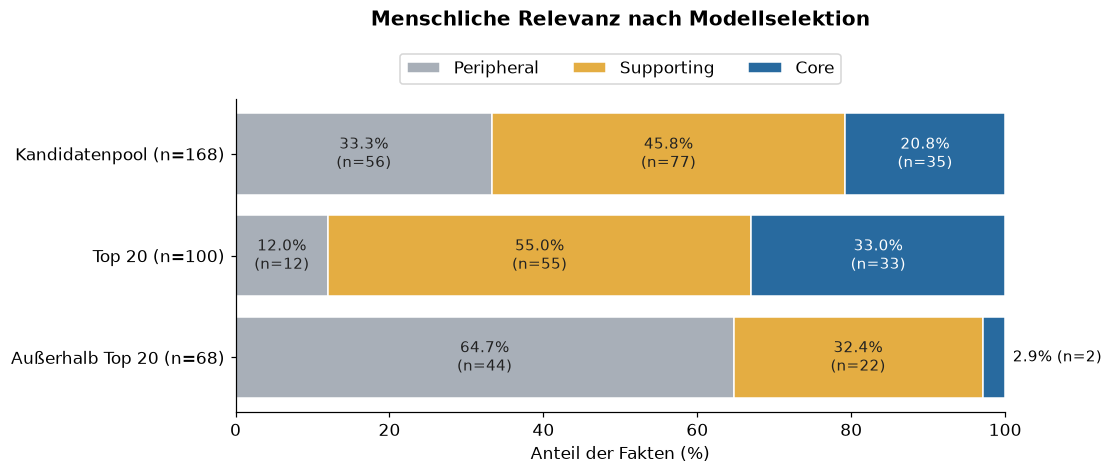

**Ergebnis:** 88 von 100 ausgewählten Fakten sind Core oder Supporting (88 %). Im Kandidatenpool sind es 112/168 (66,7 %), außerhalb der Top 20 24/68 (35,3 %). Die Top 20 enthalten 33 Core-, 55 Supporting- und 12 Peripheral-Fakten. Dieser Vergleich beschreibt die Selektionsleistung innerhalb des eingefrorenen Pools.

In [5]:
groups = {"Kandidatenpool (n=168)": df, "Top 20 (n=100)": top20,
          "Außerhalb Top 20 (n=68)": df[~df.in_top_20_laut_modell]}
composition = pd.DataFrame({name: g["median"].value_counts().reindex(range(3), fill_value=0)
                            for name, g in groups.items()}).T
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
left = np.zeros(len(composition))
for category in range(3):
    percentages = composition[category].to_numpy() / composition.sum(axis=1).to_numpy() * 100
    ax.barh(composition.index, percentages, left=left, color=colors[category],
            edgecolor="white", label=labels[category])
    for i, (pct, n) in enumerate(zip(percentages, composition[category])):
        if 0 < pct < 8:
            ax.text(101, i, f"{pct:.1f}% (n={n})", ha="left", va="center", fontsize=10)
        elif pct >= 8:
            ax.text(left[i] + pct / 2, i, f"{pct:.1f}%\n(n={n})", ha="center", va="center",
                    color="white" if category == 2 else "#222222", fontsize=10 if pct >= 8 else 7)
    left += percentages
ax.set(xlim=(0, 100), xlabel="Anteil der Fakten (%)", title="Menschliche Relevanz nach Modellselektion")
ax.invert_yaxis()
ax.legend(ncols=3, loc="lower center", bbox_to_anchor=(0.5, 1.02))
save_figure(fig, "01_relevanz_selektion")
display(Markdown("**Ergebnis:** 88 von 100 ausgewählten Fakten sind Core oder Supporting (88 %). "
    "Im Kandidatenpool sind es 112/168 (66,7 %), außerhalb der Top 20 24/68 (35,3 %). "
    "Die Top 20 enthalten 33 Core-, 55 Supporting- und 12 Peripheral-Fakten. "
    "Dieser Vergleich beschreibt die Selektionsleistung innerhalb des eingefrorenen Pools."))

## Abbildung 2: Auswahlqualität je Artikel
Die linke Seite zeigt die Zusammensetzung der jeweils 20 ausgewählten Fakten. Rechts steht, wie viele der menschlichen Core-Fakten erfasst wurden. Damit werden Präzision und Abdeckung gemeinsam sichtbar; die Artikel-ID bleibt zur Nachprüfbarkeit erhalten.

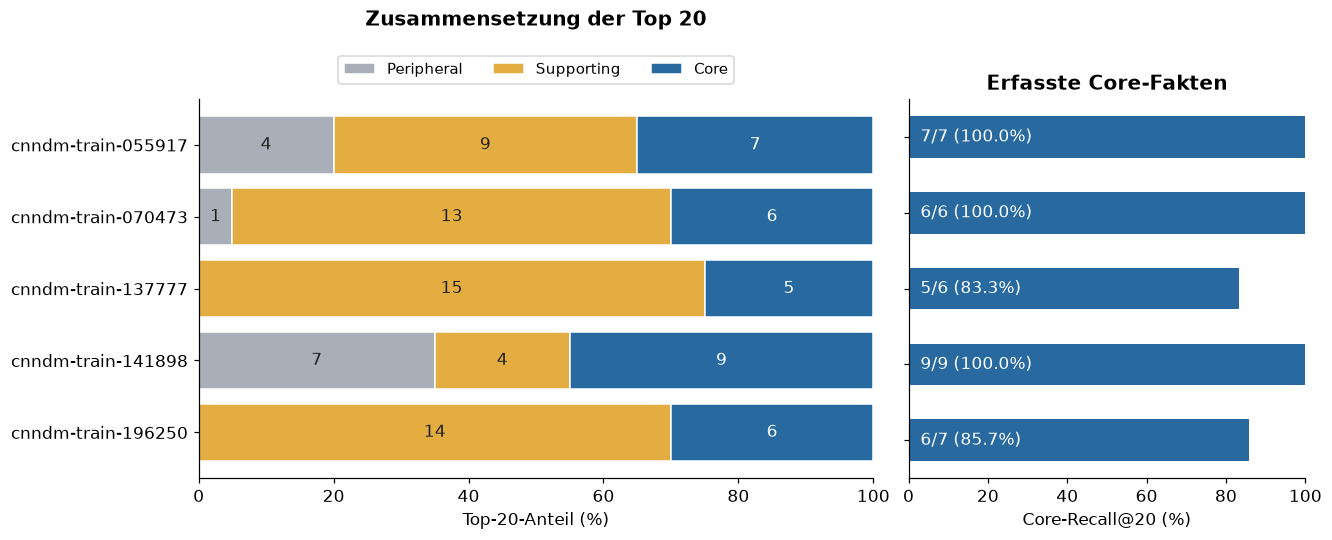

**Ergebnis:** Precision@20 reicht von 65 % bis 100 %. Artikel `cnndm-train-141898` enthält sieben Peripheral-Fakten in den Top 20, erfasst jedoch alle neun Core-Fakten. Insgesamt werden 33/35 Core-Fakten erfasst (94,3 % gepoolt); der ungewichtete Artikelmittelwert des Core-Recall beträgt 93,8 %. Zwei Core-Fakten liegen außerhalb der Top 20.

In [6]:
by_article = pd.crosstab(top20.artikel_id, top20["median"]).reindex(index=articles, columns=range(3), fill_value=0)
fig, (ax, recall_ax) = plt.subplots(1, 2, figsize=(12, 4.8), width_ratios=[1.7, 1], layout="constrained")
y = np.arange(len(articles))
left = np.zeros(len(articles))
for category in range(3):
    values = by_article[category].to_numpy() * 5
    ax.barh(y, values, left=left, color=colors[category], edgecolor="white", label=labels[category])
    for i, (value, n) in enumerate(zip(values, by_article[category])):
        if n:
            ax.text(left[i] + value / 2, i, str(n), ha="center", va="center",
                    color="white" if category == 2 else "#222222")
    left += values
ax.set(yticks=y, yticklabels=articles, xlim=(0, 100), xlabel="Top-20-Anteil (%)",
       title="Zusammensetzung der Top 20")
ax.invert_yaxis()
ax.legend(ncols=3, loc="lower center", bbox_to_anchor=(0.5, 1.02), fontsize=10)
recall = article_metrics["Core-Recall@20"].to_numpy() * 100
recall_ax.barh(y, recall, color=colors[2], height=0.55)
for i, (value, row) in enumerate(zip(recall, article_metrics.to_dict("records"))):
    recall_ax.text(3, i, f"{int(row['Core in Top 20'])}/{int(row['Core gesamt'])} ({value:.1f}%)",
                   va="center", color="white")
recall_ax.set(yticks=y, yticklabels=[], xlim=(0, 100), xlabel="Core-Recall@20 (%)",
              title="Erfasste Core-Fakten")
recall_ax.invert_yaxis()
save_figure(fig, "02_auswahl_je_artikel")
display(Markdown("**Ergebnis:** Precision@20 reicht von 65 % bis 100 %. Artikel `cnndm-train-141898` "
    "enthält sieben Peripheral-Fakten in den Top 20, erfasst jedoch alle neun Core-Fakten. "
    "Insgesamt werden 33/35 Core-Fakten erfasst (94,3 % gepoolt); der ungewichtete Artikelmittelwert "
    "des Core-Recall beträgt 93,8 %. Zwei Core-Fakten liegen außerhalb der Top 20."))

## Abbildung 3: Modell–Mensch-Konfusionsmatrix
Zeilen zeigen den menschlichen Median, Spalten die Modellbewertung. Jede Zelle enthält die Faktanzahl und den Anteil innerhalb der jeweiligen menschlichen Klasse. Die Farbintensität kodiert diesen Zeilenanteil, sodass die unterschiedlich großen Klassen vergleichbar bleiben.

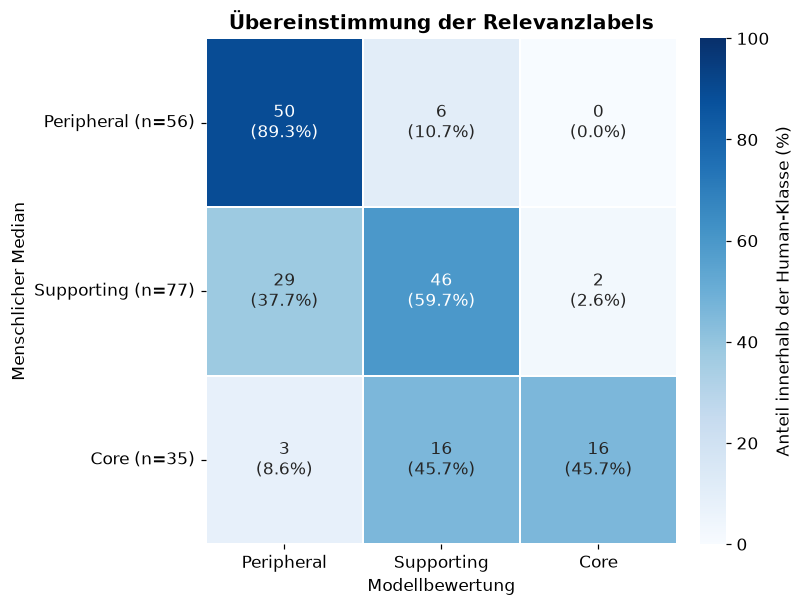

**Ergebnis:** Exakte Übereinstimmung: 66.7% (112/168), linear gewichtetes Kappa: 0.542, Macro-F1: 0.654. Das Modell stuft 19/35 menschliche Core-Fakten niedriger ein (16 Supporting, 3 Peripheral). Kein menschlicher Peripheral-Fakt wird als Core bewertet. Insgesamt unterschätzt das Modell 48 Fakten und überschätzt acht; 112 stimmen überein. Das Ranking und die Top-20-Auswahl funktionieren daher besser als die exakte Drei-Klassen-Kalibrierung.

In [7]:
confusion = pd.crosstab(df["median"], df.bewertung_modell).reindex(index=range(3), columns=range(3), fill_value=0)
row_pct = confusion.div(confusion.sum(axis=1), axis=0) * 100
annotations = np.array([[f"{confusion.iloc[i,j]}\n({row_pct.iloc[i,j]:.1f}%)"
                          for j in range(3)] for i in range(3)])
fig, ax = plt.subplots(figsize=(7.2, 5.4), layout="constrained")
sns.heatmap(row_pct, annot=annotations, fmt="", cmap="Blues", vmin=0, vmax=100,
            xticklabels=labels, yticklabels=[f"{labels[i]} (n={confusion.sum(axis=1).iloc[i]})" for i in range(3)],
            linewidths=1, cbar_kws={"label": "Anteil innerhalb der Human-Klasse (%)"}, ax=ax)
ax.set(xlabel="Modellbewertung", ylabel="Menschlicher Median", title="Übereinstimmung der Relevanzlabels")
ax.tick_params(axis="y", rotation=0)
save_figure(fig, "03_modell_mensch_konfusion")
display(Markdown(f"**Ergebnis:** Exakte Übereinstimmung: {accuracy:.1%} (112/168), "
    f"linear gewichtetes Kappa: {kappa:.3f}, Macro-F1: {macro_f1:.3f}. "
    "Das Modell stuft 19/35 menschliche Core-Fakten niedriger ein (16 Supporting, 3 Peripheral). "
    "Kein menschlicher Peripheral-Fakt wird als Core bewertet. Insgesamt unterschätzt das Modell "
    "48 Fakten und überschätzt acht; 112 stimmen überein. Das Ranking und die Top-20-Auswahl "
    "funktionieren daher besser als die exakte Drei-Klassen-Kalibrierung."))

## Abbildung 4: Unterschiede und Übereinstimmung der Teilnehmer
Links zeigen gleiche Nenner von jeweils 168 Fakten, wie streng die Teilnehmer die Klassen vergeben. Rechts wird die paarweise Übereinstimmung mit linear gewichtetem Cohen-Kappa dargestellt. Die Diagonale wird ausgeblendet, weil Selbstübereinstimmung keine zusätzliche Information liefert.

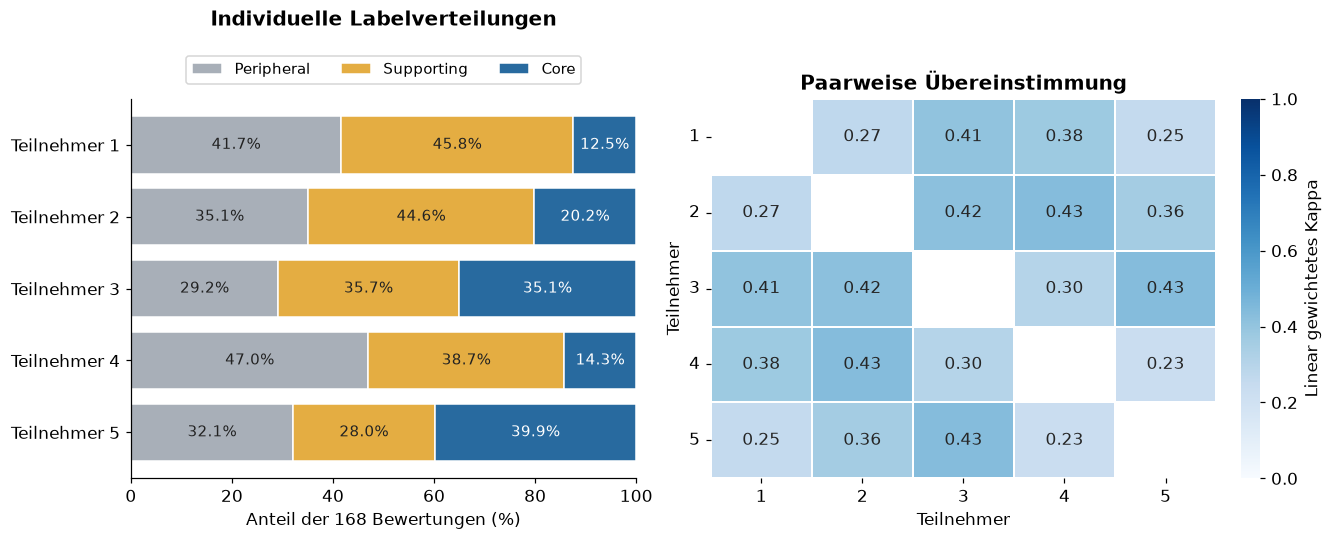

**Ergebnis:** Ordinales Krippendorff-Alpha = 0.459; alle fünf Teilnehmer stimmen bei 28/168 Fakten (16.7%) überein. Der Core-Anteil reicht von 12,5 % (Teilnehmer 1) bis 39,9 % (Teilnehmer 5). Die paarweisen gewichteten Kappas liegen zwischen 0,234 und 0,434. Diese Streuung begrenzt die Interpretation des Medians als fehlerfreie Ground-Truth.

In [8]:
reviewer_counts = pd.DataFrame({r: df[r].value_counts().reindex(range(3), fill_value=0) for r in reviewers}).T
pair_kappa = pd.DataFrame(np.nan, index=range(1, 6), columns=range(1, 6))
for i, j in combinations(range(1, 6), 2):
    pair_kappa.loc[i, j] = pair_kappa.loc[j, i] = cohen_kappa_score(df[reviewers[i-1]], df[reviewers[j-1]], weights="linear")
fig, (ax, k_ax) = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
left = np.zeros(5)
for category in range(3):
    values = reviewer_counts[category].to_numpy() / len(df) * 100
    ax.barh(range(5), values, left=left, color=colors[category], edgecolor="white", label=labels[category])
    for i, value in enumerate(values):
        ax.text(left[i] + value/2, i, f"{value:.1f}%", ha="center", va="center", fontsize=10,
                color="white" if category == 2 else "#222222")
    left += values
ax.set(yticks=range(5), yticklabels=[f"Teilnehmer {i}" for i in range(1, 6)], xlim=(0, 100),
       xlabel="Anteil der 168 Bewertungen (%)", title="Individuelle Labelverteilungen")
ax.invert_yaxis()
ax.legend(ncols=3, loc="lower center", bbox_to_anchor=(0.5, 1.02), fontsize=10)
sns.heatmap(pair_kappa, mask=pair_kappa.isna(), annot=True, fmt=".2f", vmin=0, vmax=1,
            cmap="Blues", linewidths=1, cbar_kws={"label": "Linear gewichtetes Kappa"}, ax=k_ax)
k_ax.set(xlabel="Teilnehmer", ylabel="Teilnehmer", title="Paarweise Übereinstimmung")
k_ax.tick_params(axis="y", rotation=0)
save_figure(fig, "04_teilnehmer_reliabilitaet")
display(Markdown(f"**Ergebnis:** Ordinales Krippendorff-Alpha = {alpha:.3f}; "
    f"alle fünf Teilnehmer stimmen bei {unanimous}/168 Fakten ({unanimous/168:.1%}) überein. "
    "Der Core-Anteil reicht von 12,5 % (Teilnehmer 1) bis 39,9 % (Teilnehmer 5). "
    "Die paarweisen gewichteten Kappas liegen zwischen 0,234 und 0,434. "
    "Diese Streuung begrenzt die Interpretation des Medians als fehlerfreie Ground-Truth."))

## Abbildung 5: Menschliche Relevanz entlang des Modellrankings
Jede Zelle ist ein Fakt; die Spalten sind die Modellränge. Die Linie markiert die Grenze nach Rang 20. Nicht vorhandene Ränge (Artikel mit 32 statt 34 Fakten) sind weiß und ausdrücklich fehlend, nicht Peripheral. Die diskrete Farbskala verwendet dieselben Farben wie die übrigen Abbildungen.

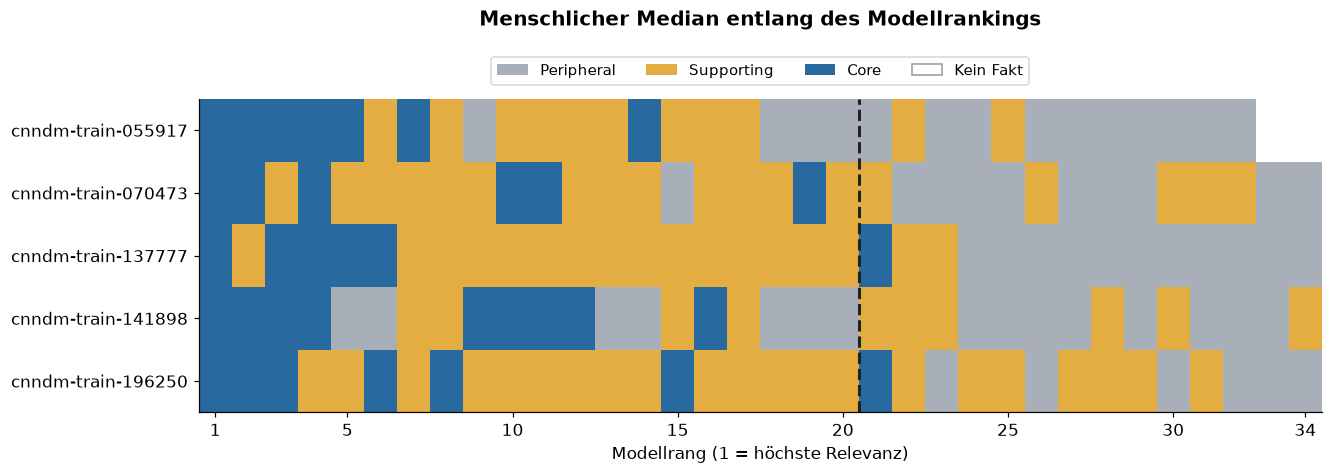

**Ergebnis:** Mittleres nDCG@20 mit linearem Gain 0/1/2 = 0.914. Das ursprüngliche nDCG mit Gain 1/3/7 beträgt 0.926. Die mittlere Spearman-Korrelation zwischen Modellrang und Human-Median beträgt -0.696. Das negative Vorzeichen ist erwartungsgemäß: Ein kleiner Rang bedeutet hohe Relevanz, ein hoher Humanscore ebenfalls. Die beiden nDCG-Werte verwenden verschiedene Gain-Definitionen und sollten im Ergebnisteil nicht austauschbar verwendet werden.

In [9]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
rank_matrix = df.pivot(index="artikel_id", columns="rang_laut_modell", values="median").reindex(index=articles, columns=range(1, 35))
fig, ax = plt.subplots(figsize=(12, 4.2), layout="constrained")
cmap = ListedColormap(colors)
cmap.set_bad("white")
ax.imshow(rank_matrix.to_numpy(), aspect="auto", cmap=cmap, norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3))
ax.axvline(19.5, color="#222222", linewidth=2, linestyle="--")
ax.set(yticks=range(5), yticklabels=articles,
       xticks=[0,4,9,14,19,24,29,33], xticklabels=[1,5,10,15,20,25,30,34],
       xlabel="Modellrang (1 = höchste Relevanz)", title="Menschlicher Median entlang des Modellrankings")
ax.legend(handles=[Patch(facecolor=colors[i], label=labels[i]) for i in range(3)]
          + [Patch(facecolor="white", edgecolor="#999999", label="Kein Fakt")],
          ncols=4, loc="lower center", bbox_to_anchor=(0.5, 1.02), fontsize=10)
save_figure(fig, "05_relevanz_nach_modellrang")
display(Markdown(f"**Ergebnis:** Mittleres nDCG@20 mit linearem Gain 0/1/2 = "
    f"{article_metrics['nDCG@20 (linear 0/1/2)'].mean():.3f}. "
    f"Das ursprüngliche nDCG mit Gain 1/3/7 beträgt {article_metrics['nDCG@20 (Original 1/3/7)'].mean():.3f}. "
    f"Die mittlere Spearman-Korrelation zwischen Modellrang und Human-Median beträgt "
    f"{article_metrics['Spearman Rang–Median'].mean():.3f}. "
    "Das negative Vorzeichen ist erwartungsgemäß: Ein kleiner Rang bedeutet hohe Relevanz, "
    "ein hoher Humanscore ebenfalls. Die beiden nDCG-Werte verwenden verschiedene Gain-Definitionen "
    "und sollten im Ergebnisteil nicht austauschbar verwendet werden."))

## Abbildung 6: Übereinstimmung jedes Teilnehmers mit der KI
Für jeden Teilnehmer werden dieselben 168 Fakten mit der Modellbewertung verglichen. Die exakte Übereinstimmung zählt identische Kategorien; linear gewichtetes Cohen-Kappa berücksichtigt Zufallsübereinstimmung und die ordinale Entfernung der Kategorien. Macro-F1 mittelt die F1-Werte der drei Kategorien gleichgewichtet. „KI niedriger“ und „KI höher“ beziehen sich jeweils auf das individuelle Teilnehmerurteil. Die Kennzahlen messen Übereinstimmung, nicht die objektive Richtigkeit eines Teilnehmers. Wegen der fünf gemeinsamen Artikel werden Unterschiede deskriptiv ausgewiesen.

,Fakten,Identische Bewertungen,Exakte Übereinstimmung,Cohen-Kappa (linear gewichtet),Macro-F1,KI niedriger,KI höher,Relevanter Anteil der Top 20
Teilnehmer,,,,,,,,
Teilnehmer 1,168,109,0.6488,0.4838,0.5891,37,22,0.79
Teilnehmer 2,168,100,0.5952,0.4146,0.5591,53,15,0.86
Teilnehmer 3,168,90,0.5357,0.4306,0.5256,73,5,0.89
Teilnehmer 4,168,101,0.6012,0.4120,0.5309,37,30,0.73
Teilnehmer 5,168,78,0.4643,0.2919,0.4432,76,14,0.81


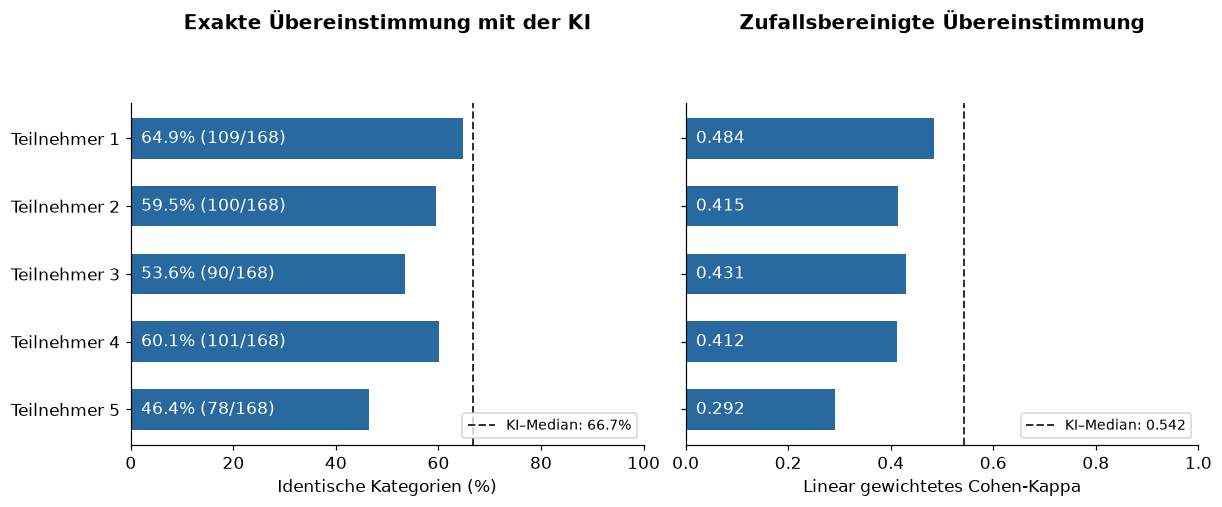

**Ergebnis:** Die exakte Übereinstimmung der einzelnen Teilnehmer mit der KI reicht von 46.4% bis 64.9%. Die höchste exakte Übereinstimmung erreicht Teilnehmer 1, die niedrigste Teilnehmer 5. Das linear gewichtete Kappa reicht von 0.292 bis 0.484; den höchsten Wert erreicht Teilnehmer 1. Die gestrichelten Linien zeigen den Vergleich der KI mit dem menschlichen Median als Referenz. Der Median wird aus diesen fünf Teilnehmerurteilen gebildet und ist keine unabhängige weitere Bewertung. Eine hohe KI-Übereinstimmung bedeutet nicht automatisch eine bessere menschliche Bewertung.

In [10]:
participant_rows = []
for number, column in enumerate(reviewers, 1):
    human = df[column]
    model = df["bewertung_modell"]
    participant_rows.append({
        "Teilnehmer": f"Teilnehmer {number}", "Fakten": len(df),
        "Identische Bewertungen": int(human.eq(model).sum()),
        "Exakte Übereinstimmung": accuracy_score(human, model),
        "Cohen-Kappa (linear gewichtet)": cohen_kappa_score(human, model, labels=[0, 1, 2], weights="linear"),
        "Macro-F1": f1_score(human, model, labels=[0, 1, 2], average="macro", zero_division=0),
        "KI niedriger": int(model.lt(human).sum()),
        "KI höher": int(model.gt(human).sum()),
        "Relevanter Anteil der Top 20": df.loc[df.in_top_20_laut_modell, column].ge(1).mean(),
    })
participant_model_metrics = pd.DataFrame(participant_rows).set_index("Teilnehmer")
assert participant_model_metrics[["Identische Bewertungen", "KI niedriger", "KI höher"]].sum(axis=1).eq(len(df)).all()
display(participant_model_metrics.round(4))
participant_model_metrics.to_csv(FIG_DIR / "teilnehmer_ki_uebereinstimmung.csv", encoding="utf-8-sig")

fig, (agreement_ax, kappa_ax) = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
y = np.arange(5)
agreement = participant_model_metrics["Exakte Übereinstimmung"].to_numpy() * 100
agreement_ax.barh(y, agreement, color=colors[2], height=0.6)
for i, (value, count) in enumerate(zip(agreement, participant_model_metrics["Identische Bewertungen"])):
    agreement_ax.text(2, i, f"{value:.1f}% ({count}/168)", color="white", va="center")
agreement_ax.axvline(accuracy * 100, color="#333333", linestyle="--", linewidth=1.3,
                     label=f"KI–Median: {accuracy:.1%}")
agreement_ax.set(yticks=y, yticklabels=participant_model_metrics.index,
                 xlim=(0, 100), xlabel="Identische Kategorien (%)", title="Exakte Übereinstimmung mit der KI")
agreement_ax.invert_yaxis()
agreement_ax.legend(loc="lower right", fontsize=9)
weighted_kappas = participant_model_metrics["Cohen-Kappa (linear gewichtet)"].to_numpy()
kappa_ax.barh(y, weighted_kappas, color=colors[2], height=0.6)
for i, value in enumerate(weighted_kappas):
    kappa_ax.text(0.02, i, f"{value:.3f}", color="white", va="center")
kappa_ax.axvline(kappa, color="#333333", linestyle="--", linewidth=1.3, label=f"KI–Median: {kappa:.3f}")
kappa_ax.set(yticks=y, yticklabels=[], xlim=(0, 1), xlabel="Linear gewichtetes Cohen-Kappa",
             title="Zufallsbereinigte Übereinstimmung")
kappa_ax.invert_yaxis()
kappa_ax.legend(loc="lower right", fontsize=9)
save_figure(fig, "06_teilnehmer_ki_uebereinstimmung")

best_exact = participant_model_metrics["Exakte Übereinstimmung"].idxmax()
best_kappa = participant_model_metrics["Cohen-Kappa (linear gewichtet)"].idxmax()
lowest = participant_model_metrics["Exakte Übereinstimmung"].idxmin()
display(Markdown(
    f"**Ergebnis:** Die exakte Übereinstimmung der einzelnen Teilnehmer mit der KI reicht von "
    f"{participant_model_metrics['Exakte Übereinstimmung'].min():.1%} bis "
    f"{participant_model_metrics['Exakte Übereinstimmung'].max():.1%}. "
    f"Die höchste exakte Übereinstimmung erreicht {best_exact}, die niedrigste {lowest}. "
    f"Das linear gewichtete Kappa reicht von {weighted_kappas.min():.3f} bis {weighted_kappas.max():.3f}; "
    f"den höchsten Wert erreicht {best_kappa}. "
    "Die gestrichelten Linien zeigen den Vergleich der KI mit dem menschlichen Median als Referenz. "
    "Der Median wird aus diesen fünf Teilnehmerurteilen gebildet und ist keine unabhängige weitere Bewertung. "
    "Eine hohe KI-Übereinstimmung bedeutet nicht automatisch eine bessere menschliche Bewertung."
))

## Formulierungsvorschlag für den Ergebnisteil

Die Human Validation umfasste 168 Kandidatenfakten aus fünf Artikeln, die von jeweils fünf Teilnehmern bewertet wurden (840 Relevanzurteile). Als aggregierte menschliche Bewertung wurde der Median der ordinalen Relevanzlabels verwendet. Von den 100 durch das Modell ausgewählten Top-20-Fakten wurden 33 als Core, 55 als Supporting und zwölf als Peripheral eingestuft. Somit waren 88 % der ausgewählten Fakten nach menschlichem Median relevant (Core oder Supporting; Abbildung 1). Die Auswahl erfasste 33 von insgesamt 35 menschlichen Core-Fakten, entsprechend einem gepoolten Core-Recall von 94,3 %. Der ungewichtete mittlere Core-Recall über die fünf Artikel betrug 93,8 %.

Die Auswahlqualität unterschied sich zwischen den Artikeln: Precision@20 lag zwischen 65 % und 100 % (Abbildung 2). Der Artikel `cnndm-train-141898` wies mit sieben Peripheral-Fakten unter den 20 ausgewählten Fakten den niedrigsten Wert auf, obwohl alle neun Core-Fakten dieses Artikels erfasst wurden. Die relative Modellrangfolge erreichte ein mittleres nDCG@20 von 0,914 bei linearem Gain 0/1/2. Die mittlere Spearman-Korrelation zwischen Modellrang und menschlichem Median betrug −0,696 (Abbildung 5).

Die exakte Übereinstimmung zwischen Modelllabel und menschlichem Median lag bei 66,7 % (112/168 Fakten), das linear gewichtete Cohen-Kappa bei 0,542 und Macro-F1 bei 0,654. Das Modell bewertete 19 der 35 menschlichen Core-Fakten als Supporting oder Peripheral. Insgesamt wurden 48 Fakten niedriger und acht höher bewertet als im menschlichen Median (Abbildung 3). Damit erwiesen sich Top-20-Selektion und relative Rangfolge in dieser Stichprobe als geeigneter als die exakte Kalibrierung der drei Relevanzklassen.

Die Übereinstimmung der Teilnehmer betrug im ordinalen Krippendorff-Alpha 0,459. Bei 28 von 168 Fakten (16,7 %) vergaben alle fünf Teilnehmer dasselbe Label. Der individuelle Core-Anteil variierte zwischen 12,5 % und 39,9 % (Abbildung 4). Die aggregierten Medianlabels sind daher als subjektive Konsensbewertung zu interpretieren. Die geringe Zahl von fünf Artikeln und die Abhängigkeit der Fakten innerhalb eines Artikels begrenzen die Übertragbarkeit der Ergebnisse.

### Empfohlene Auswahl für die Arbeit
Abbildungen 1–3 bilden den Kern des Ergebnisteils: Selektion, Artikelunterschiede und Modellkalibrierung. Abbildung 4 ergänzt die Reliabilität; Abbildung 5 eignet sich zur anschaulichen Rankingdiagnostik. Die Entitätstypen sind für eine explorative Zusatzanalyse verfügbar, wegen kleiner Gruppen und der Vermischung mit Artikelthemen aber keine primäre Validierungsaussage.

Alle Abbildungen werden bei Ausführung als PNG (300 dpi) und PDF in `human_validation_grafiken/` gespeichert. Die Kennzahlen sind zusätzlich als CSV exportiert. Benötigte Python-Pakete: pandas, numpy, matplotlib, seaborn, scipy und scikit-learn.